# Compile TSA-wise slash burning proportion

This notebook compiles the TSA-wise proportion of area harvested to "piggyback" as slashburing disturbances in the SHA module. 

The basic idea here is that we assume 15% slashburning proportion value for the Maritime Pacific ecozone (i.e., ecozone 13), and 50% everywhere else. The trick is that some TSAs may be part-in and part-out of the ecozone 13. We calculate the proportion of area in ecozone 13 for each TSA, and use this to calculate a TSA-wise prorated slashburning coefficients.

In [37]:
%matplotlib inline
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

In [38]:
prop_mp, prop_other = 0.15, 0.50

In [47]:
gdf = gpd.read_file('../dat/gis/BC_out.shp').set_index('AdminBound') #.query("EcoBoundar == 13")

In [48]:
#gdf.query("EcoBoundar == 13")

In [49]:
#gdf.apply(lambda r: print(r), axis=1)

(-1950797.9558050008,
 -1750085.8308950008,
 1298957.4304599992,
 1601872.261140001)

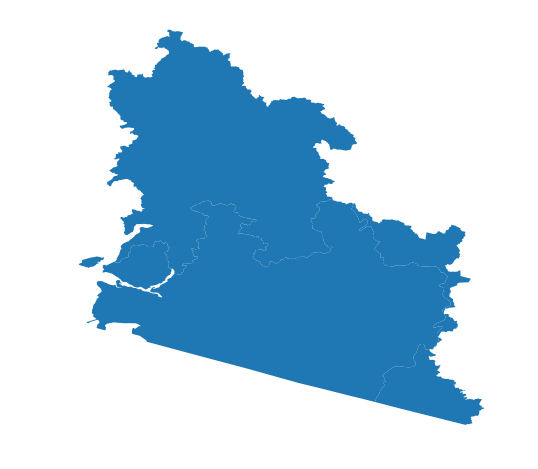

In [51]:
fig, ax = plt.subplots(figsize=(8, 8))
tsaids = [30, 31]
gdf = gdf.loc[tsaids]
gdf.plot(ax=ax)
ax.axis('off')
#gdf.apply(lambda r: ax.annotate(s=r.AdminBou, xy=r.geometry.centroid.coords[0], ha='center'),axis=1);
#gdf.apply(lambda r: print(r.columns))

In [13]:
gdf[['AdminBound', 'AdminBou_1']]

,AdminBound,AdminBou_1
0,40,40_Fort St. John
1,8,08_Fort Nelson
2,41,41_Dawson Creek
3,40,40_Fort St. John
4,8,08_Fort Nelson
5,243,24dja_Fort St. James
6,16,16_Mackenzie
7,4,04_Cassiar
8,40,40_Fort St. John
9,8,08_Fort Nelson


In [7]:
len(gdf.AdminBound.unique())

44

In [8]:
gdf = gdf.set_index('AdminBound')
ix_vals = gdf.index.unique()
pm_props = {}
for i in range(len(ix_vals)):
    a1, a2 = 0., 0.
    r = gdf.loc[[ix_vals[i]]]
    for j in range(len(r)):
        a1 += r.iloc[j]['Shape_Area']
        if r.iloc[j]['EcoBoundar'] == 13:
            a2 += r.iloc[j]['Shape_Area']
    pm_props[ix_vals[i]] = a2 / a1

In [9]:
slashburn_coeffs = {k:(prop_other * (1 - v) + prop_mp * v) for k, v in pm_props.items()}

In [11]:
def read_basenames(path):
    return [line.lower().strip().split(' ')[0] 
        for line in open(path, 'r') if not line.startswith('#')]
basenames = read_basenames('../dat/basenames.txt')

In [14]:
with open('../dat/p_slashburn.csv', 'w') as snk:
    for k, v in slashburn_coeffs.items():
        bn = 'tsa' + str(k).zfill(2)
        if bn not in basenames: continue
        #print '%s\t%0.2f' % (bn, v)
        snk.write('%s,%0.2f\n' % (bn, v))

In [16]:
def read_pslashburn(path):
    result = {}
    for line in open(path, 'r'):
        if line.strip().startswith('#'): continue
        k, v = line.lower().strip().split(',')
        result[k] = float(v)
    return result
p_slashburn = read_pslashburn('../dat/p_slashburn.csv')
p_slashburn

{'tsa01': 0.5,
 'tsa02': 0.5,
 'tsa03': 0.45,
 'tsa04': 0.45,
 'tsa05': 0.5,
 'tsa07': 0.5,
 'tsa08': 0.5,
 'tsa09': 0.5,
 'tsa10': 0.15,
 'tsa12': 0.35,
 'tsa13': 0.5,
 'tsa14': 0.5,
 'tsa15': 0.5,
 'tsa16': 0.5,
 'tsa17': 0.5,
 'tsa18': 0.5,
 'tsa19': 0.21,
 'tsa20': 0.45,
 'tsa21': 0.15,
 'tsa23': 0.5,
 'tsa25': 0.15,
 'tsa26': 0.5,
 'tsa27': 0.5,
 'tsa30': 0.21,
 'tsa31': 0.15,
 'tsa33': 0.16,
 'tsa37': 0.15,
 'tsa38': 0.15,
 'tsa39': 0.15,
 'tsa40': 0.5,
 'tsa41': 0.5,
 'tsa43': 0.34}